In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from lightgbm import LGBMClassifier

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    ConfusionMatrixDisplay
)

from imblearn.over_sampling import SMOTE

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
X_train = pd.read_csv("../Data/processed/X_train.csv")
y_train = pd.read_csv("../Data/processed/y_train.csv").squeeze()

X_test = pd.read_csv("../Data/processed/X_test.csv")
y_test = pd.read_csv("../Data/processed/y_test.csv").squeeze()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

X_train: (198608, 30)
y_train: (198608,)
X_test: (85118, 30)
y_test: (85118,)

Training class distribution:
Class
0    198277
1       331
Name: count, dtype: int64

Test class distribution:
Class
0    84976
1      142
Name: count, dtype: int64


In [3]:
X_train_lgbm, X_val_lgbm, y_train_lgbm, y_val_lgbm = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training Shape:", X_train_lgbm.shape)
print("Validation Shape:", X_val_lgbm.shape)

print("\nTraining Class Distribution:")
print(y_train_lgbm.value_counts())

print("\nValidation Class Distribution:")
print(y_val_lgbm.value_counts())

Training Shape: (158886, 30)
Validation Shape: (39722, 30)

Training Class Distribution:
Class
0    158621
1       265
Name: count, dtype: int64

Validation Class Distribution:
Class
0    39656
1       66
Name: count, dtype: int64


In [4]:
smote = SMOTE(random_state=42)

X_train_smote_lgbm, y_train_smote_lgbm = smote.fit_resample(
    X_train_lgbm,
    y_train_lgbm
)

print("SMOTE applied successfully.")

print("SMOTE Training Shape:", X_train_smote_lgbm.shape)

print("\nClass Distribution After SMOTE:")
print(y_train_smote_lgbm.value_counts())

C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Program Files\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Program Files\Python313\Lib\subprocess.py", line 1036, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~

SMOTE applied successfully.
SMOTE Training Shape: (317242, 30)

Class Distribution After SMOTE:
Class
0    158621
1    158621
Name: count, dtype: int64


In [5]:
model_lgbm = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=-1,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

print("LightGBM model created.")

LightGBM model created.


In [6]:
model_lgbm.fit(
    X_train_smote_lgbm,
    y_train_smote_lgbm
)

print("LightGBM trained successfully.")

LightGBM trained successfully.


In [7]:
y_val_prob_lgbm = model_lgbm.predict_proba(X_val_lgbm)[:, 1]

thresholds = np.arange(0.1, 1.0, 0.1)

threshold_results = []

for threshold in thresholds:

    y_val_pred = (y_val_prob_lgbm >= threshold).astype(int)

    precision = precision_score(
        y_val_lgbm, y_val_pred, zero_division=0
    )

    recall = recall_score(
        y_val_lgbm, y_val_pred, zero_division=0
    )

    f1 = f1_score(
        y_val_lgbm, y_val_pred, zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

threshold_df_lgbm = pd.DataFrame(threshold_results)

display(threshold_df_lgbm.round(4))

best_index = threshold_df_lgbm["F1-Score"].idxmax()

final_threshold_lgbm = threshold_df_lgbm.loc[
    best_index, "Threshold"
]

print("Selected Threshold:", final_threshold_lgbm)

,Threshold,Precision,Recall,F1-Score
0,0.1,0.4231,0.8333,0.5612
1,0.2,0.5729,0.8333,0.6790
2,0.3,0.6707,0.8333,0.7432
3,0.4,0.7333,0.8333,0.7801
4,0.5,0.7714,0.8182,0.7941
5,0.6,0.8308,0.8182,0.8244
6,0.7,0.8413,0.8030,0.8217
7,0.8,0.8689,0.8030,0.8346
8,0.9,0.9138,0.8030,0.8548


Selected Threshold: 0.9


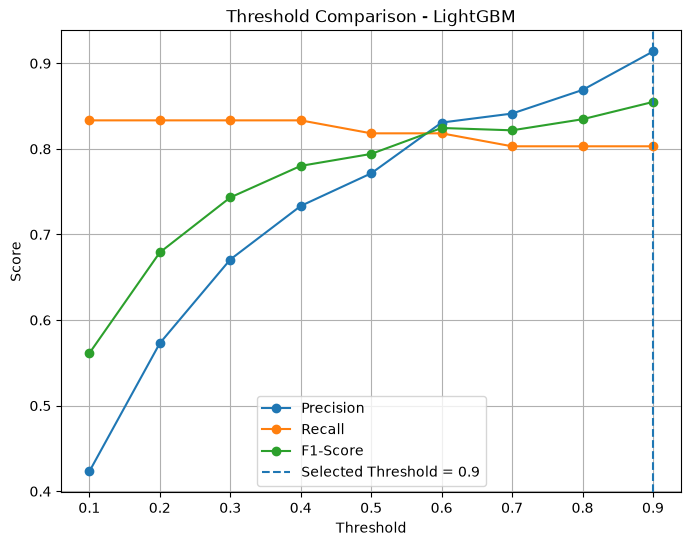

In [8]:
plt.figure(figsize=(8, 6))

plt.plot(
    threshold_df_lgbm["Threshold"],
    threshold_df_lgbm["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df_lgbm["Threshold"],
    threshold_df_lgbm["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df_lgbm["Threshold"],
    threshold_df_lgbm["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.axvline(
    final_threshold_lgbm,
    linestyle="--",
    label=f"Selected Threshold = {final_threshold_lgbm:.1f}"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold Comparison - LightGBM")

plt.legend()
plt.grid()
plt.show()

In [9]:
y_prob_lgbm = model_lgbm.predict_proba(X_test)[:, 1]

y_pred_lgbm = (
    y_prob_lgbm >= final_threshold_lgbm
).astype(int)

print("LightGBM Test Predictions Completed.")

LightGBM Test Predictions Completed.


In [10]:
print("Classification Report - LightGBM")

print(classification_report(y_test, y_pred_lgbm))

precision_lgbm = precision_score(y_test, y_pred_lgbm)
recall_lgbm = recall_score(y_test, y_pred_lgbm)
f1_lgbm = f1_score(y_test, y_pred_lgbm)

roc_auc_lgbm = roc_auc_score(y_test, y_prob_lgbm)

pr_auc_lgbm = average_precision_score(y_test, y_prob_lgbm)

print("Precision:", round(precision_lgbm, 4))
print("Recall:", round(recall_lgbm, 4))
print("F1-score:", round(f1_lgbm, 4))
print("ROC-AUC:", round(roc_auc_lgbm, 4))
print("PR-AUC:", round(pr_auc_lgbm, 4))

Classification Report - LightGBM
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     84976
           1       0.92      0.70      0.80       142

    accuracy                           1.00     85118
   macro avg       0.96      0.85      0.90     85118
weighted avg       1.00      1.00      1.00     85118

Precision: 0.9174
Recall: 0.7042
F1-score: 0.7968
ROC-AUC: 0.9599
PR-AUC: 0.7114


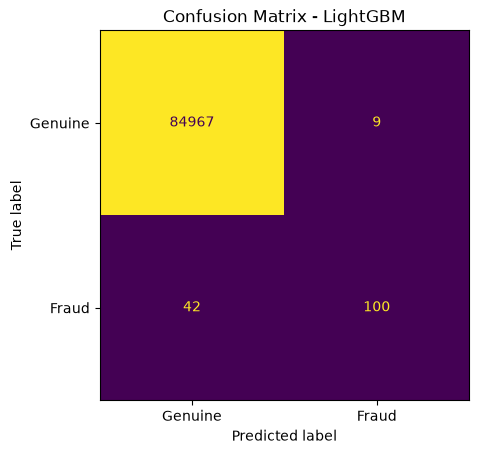

In [11]:
cm_lgbm = confusion_matrix(y_test, y_pred_lgbm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lgbm,
    display_labels=["Genuine", "Fraud"]
)

disp.plot(colorbar=False)

plt.title("Confusion Matrix - LightGBM")
plt.show()

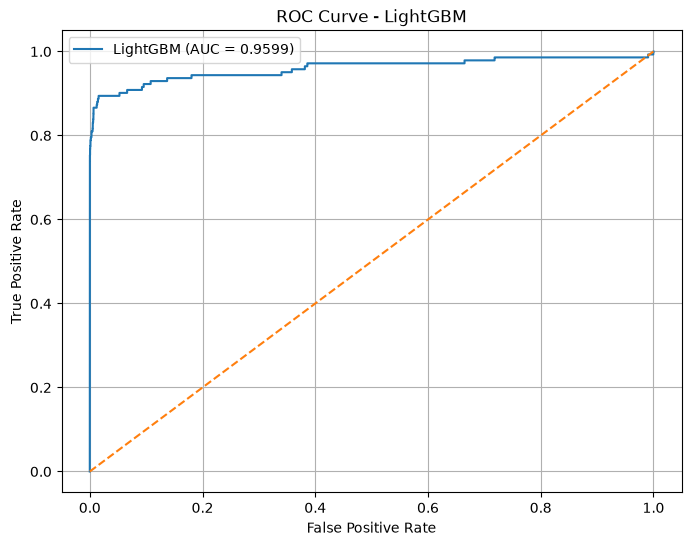

In [12]:
fpr_lgbm, tpr_lgbm, _ = roc_curve(y_test, y_prob_lgbm)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lgbm,
    tpr_lgbm,
    label=f"LightGBM (AUC = {roc_auc_lgbm:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - LightGBM")

plt.legend()
plt.grid()
plt.show()

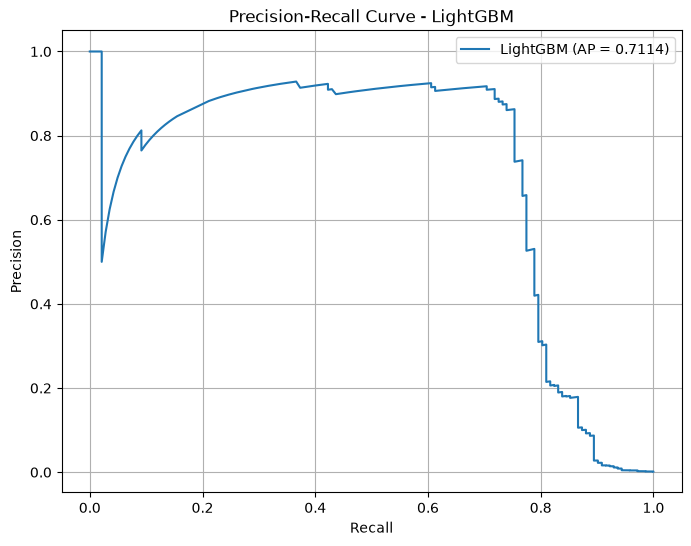

In [13]:
precision_lgbm_curve, recall_lgbm_curve, _ = precision_recall_curve(
    y_test,
    y_prob_lgbm
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_lgbm_curve,
    precision_lgbm_curve,
    label=f"LightGBM (AP = {pr_auc_lgbm:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve - LightGBM")

plt.legend()
plt.grid()
plt.show()

In [14]:
feature_importance_lgbm = pd.DataFrame({
    "Feature": X_train_smote_lgbm.columns,
    "Importance": model_lgbm.feature_importances_
})

feature_importance_lgbm = feature_importance_lgbm.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_lgbm.head(15))

,Feature,Importance
14,V14,248
4,V4,205
12,V12,170
3,V3,158
11,V11,130
10,V10,124
17,V17,122
19,V19,119
0,Time,119
7,V7,113


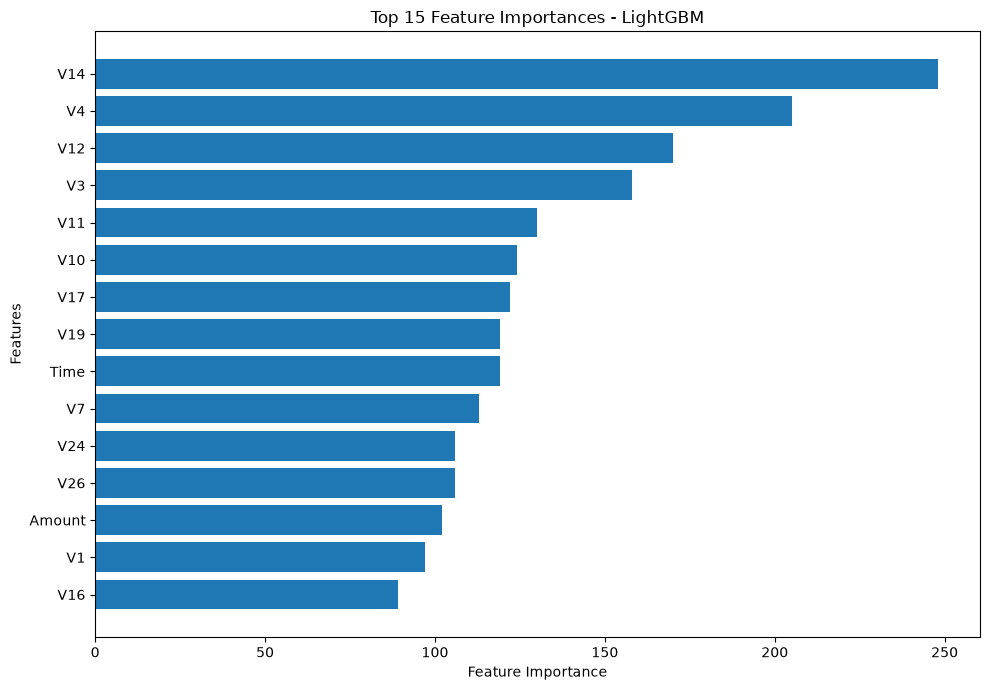

In [15]:
top_features_lgbm = feature_importance_lgbm.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features_lgbm["Feature"],
    top_features_lgbm["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.title("Top 15 Feature Importances - LightGBM")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()